# **Imports and downloads**

In [ ]:
# !pip install gdown
# Use it only if you have missing package error while using code below to download homework data floader

## **Unzipping**

In [15]:
import matplotlib.pyplot as plt


In [1]:
import os, glob, zipfile, subprocess, sys
import numpy as np
import pandas as pd

# Code if there won`t be any loaded files to work with
# if not os.path.exists("homework_data"):
#     import gdown
#     gdown.download(id="1nzrtQpfaHL0OgJ_eXzA7VuEj7XotrSWO", output="homework.zip")
#     zipfile.ZipFile("homework.zip").extractall("homework_data")

# Unzipping (delete this part of code if you download file from google drive)
r = "correctly"
try:
  zipfile.ZipFile("homework.zip").extractall("homework_data")
except zipfile.BadZipFile:
  r = "badly"
  raise "Error while unzipping file."
except FileNotFoundError:
  r = "badly"
  raise "File not found."
finally:
  print(f"Unzipping finished {r}.")

Unzipping finished correctly.


## **Preparing some information about dataset**

In [3]:
files = glob.glob("homework_data/**/*.csv", recursive=True)
files = [f for f in files if "__MACOSX" not in f]
print(len(files))
for f in files[:5]:
    print(f)

6462
homework_data/data/stairs/stairs-100.csv
homework_data/data/stairs/stairs-103.csv
homework_data/data/stairs/stairs-118.csv
homework_data/data/stairs/stairs-61.csv
homework_data/data/stairs/stairs-81.csv


In [4]:
d = pd.read_csv(files[0])
print(d.shape)
display(d.head())
print(d.columns.tolist())

(30, 3)


,accelerometer_X,accelerometer_Y,accelerometer_Z
0,-2.269703,-2.782062,2.398990
1,1.479617,-9.251195,-0.857124
2,5.152323,-11.702858,-2.279280
3,1.637634,-22.720974,-10.491392
4,-2.346318,-3.270479,1.063026


['accelerometer_X', 'accelerometer_Y', 'accelerometer_Z']


In [5]:
lengths = [len(pd.read_csv(f)) for f in files[:200]]
print(min(lengths), max(lengths))

30 30


## **Let`s count examples to test them**

In [6]:
from collections import Counter

cols = ["accelerometer_X", "accelerometer_Y", "accelerometer_Z"]
X_raw, y, bad = [], [], []

for f in files:
    d = pd.read_csv(f)
    arr = d[cols].to_numpy()
    if arr.shape != (30, 3):
        bad.append(f)
        continue
    X_raw.append(arr)
    y.append(f.replace("\\", "/").split("/")[-2])

X_raw = np.array(X_raw)
y = np.array(y)

# Saving values to numpy files to save time next time
np.save("X_raw.npy", X_raw)
np.save("y.npy", y)

print(X_raw.shape)
print("broken non-standard files count is:", len(bad))
print(Counter(y))

(6462, 30, 3)
broken non-standard files count is: 0
Counter({np.str_('running'): 3408, np.str_('walking'): 1850, np.str_('idle'): 1039, np.str_('stairs'): 165})


## ⬇

In [7]:
# vector module: the overall "strength" of movement, regardless of the phone's orientation
mag = np.sqrt((X_raw ** 2).sum(axis=2))                    # (6462, 30)
A = np.concatenate([X_raw, mag[:, :, None]], axis=2)       # (6462, 30, 4): x, y, z, mag

mean   = A.mean(axis=1)                                    # (6462, 4)
std    = A.std(axis=1)
mn     = A.min(axis=1)
mx     = A.max(axis=1)
median = np.median(A, axis=1)
rng    = mx - mn
mad    = np.abs(A - mean[:, None, :]).mean(axis=1)

X_feat = np.hstack([mean, std, mn, mx, median, rng, mad])
print(mean.shape, X_feat.shape)

(6462, 4) (6462, 28)


***cheching***

In [8]:
names = ["x", "y", "z", "mag"]
display(pd.DataFrame(std, columns=names).groupby(y).mean().round(2))

,x,y,z,mag
idle,0.39,0.65,0.49,0.31
running,8.96,12.15,6.59,10.16
stairs,3.30,4.70,4.88,5.22
walking,4.10,5.73,6.68,6.38


## **SVM**

In [10]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(y))
tr, te = train_test_split(idx, test_size=0.3, stratify=y, random_state=42)

sets = {
    "A: raw x,y,z":    X_raw.reshape(len(y), -1),
    "B: time signs": X_feat,
}
for name, X in sets.items():
    print(name, X[tr].shape, X[te].shape)
print(Counter(y[te]))

A: raw x,y,z (4523, 90) (1939, 90)
B: time signs (4523, 28) (1939, 28)
Counter({np.str_('running'): 1023, np.str_('walking'): 555, np.str_('idle'): 312, np.str_('stairs'): 49})


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

models = {
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           random_state=42, n_jobs=-1),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=42)),
}

for set_name, X in sets.items():
    for m_name, model in models.items():
        model.fit(X[tr], y[tr])
        pred = model.predict(X[te])
        print(f"\n=== {m_name} | {set_name} ===")
        print(classification_report(y[te], pred))


=== RandomForest | A: raw x,y,z ===
              precision    recall  f1-score   support

        idle       1.00      1.00      1.00       312
     running       1.00      1.00      1.00      1023
      stairs       1.00      0.04      0.08        49
     walking       0.92      1.00      0.96       555

    accuracy                           0.98      1939
   macro avg       0.98      0.76      0.76      1939
weighted avg       0.98      0.98      0.97      1939


=== SVM | A: raw x,y,z ===
              precision    recall  f1-score   support

        idle       1.00      1.00      1.00       312
     running       1.00      1.00      1.00      1023
      stairs       0.44      0.63      0.52        49
     walking       0.97      0.93      0.95       555

    accuracy                           0.97      1939
   macro avg       0.85      0.89      0.87      1939
weighted avg       0.98      0.97      0.97      1939


=== RandomForest | B: time signs ===
              precision    

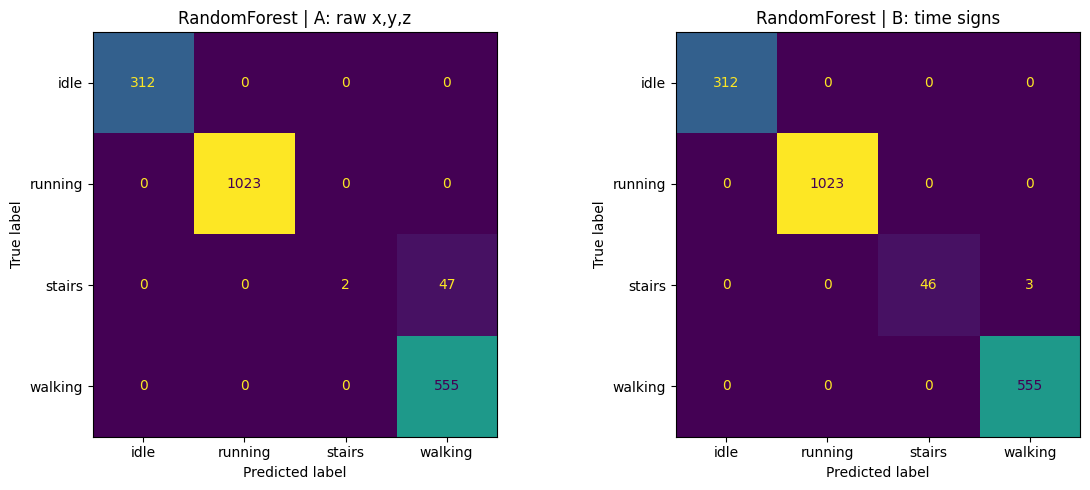

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, set_name in zip(axes, ["A: raw x,y,z", "B: time signs"]):
    X = sets[set_name]
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=42, n_jobs=-1)
    rf.fit(X[tr], y[tr])
    ConfusionMatrixDisplay.from_predictions(y[te], rf.predict(X[te]), ax=ax, colorbar=False)
    ax.set_title(f"RandomForest | {set_name}")
plt.tight_layout(); plt.show()

## Порівняння моделей

| Модель | Ознаки | accuracy | macro-F1 | stairs: precision | stairs: recall | stairs: F1 |
|---|---|---|---|---|---|---|
| RandomForest | A: сирі x,y,z | 0.98 | 0.76 | 1.00 | 0.04 | 0.08 |
| SVM | A: сирі x,y,z | 0.97 | 0.87 | 0.44 | 0.63 | 0.52 |
| RandomForest | B: часові ознаки | 1.00 | 0.99 | 1.00 | 0.94 | 0.97 |
| SVM | B: часові ознаки | 0.98 | 0.92 | 0.59 | 0.94 | 0.72 |

## Висновки

Клас `stairs` найрідкісніший (165 із 6462 файлів, близько 2.5%), тому accuracy майже не відрізняється між моделями (0.97–1.00) і приховує реальну якість. Тому порівняння зроблено за macro-F1 і за precision/recall/F1 для `stairs`.

На сирих даних x, y, z RandomForest майже не розпізнає сходи: recall 0.04, 47 із 49 файлів зі сходами він назвав ходьбою (macro-F1 0.76). SVM із масштабуванням впорався краще (macro-F1 0.87), але має низький precision для `stairs` (0.44), тобто часто називає ходьбу сходами.

Після розрахунку часових ознак (mean, std, min, max, median, range, MAD для осей x, y, z та модуля вектора) обидві моделі покращились. RandomForest отримав macro-F1 0.99 і F1 для `stairs` 0.97 (з 49 файлів знайшов 46). SVM отримав macro-F1 0.92: recall для `stairs` теж 0.94, але precision лише 0.59.

Ознаки допомагають, бо описують характер руху (наскільки сильно і широко трясе) і не залежать від того, в який момент почався запис, тоді як 90 сирих значень залежать від порядку.

Найкраща комбінація: RandomForest на часових ознаках. Класи `idle` і `running` розпізнаються ідеально в усіх варіантах, а найскладніше розрізнити `stairs` і `walking`. Обмеження: розбиття на train/test випадкове, тому якщо сусідні файли є шматками одного запису, метрики можуть бути трохи оптимістичними.